## Decision Tree (Gini / Entropy)
### Pima Indians Diabetes Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize ONE model. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
All 4-5 exercises in this group project use:
- the **same dataset**
- the **same cleaning steps**
- the **same train/test split** (fixed `random_state=42`, `test_size=0.2`)
- the **same number of required evaluation metrics** (4)
- the **same number of required visualizations** (3)

- > This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **algorithm itself**, not from different data handling. 
- > Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better as consistency across the group matters more here than optimizing your individual score.

---


## 1. Dataset

**File:** `diabetes.csv` in [Pima Indians Diabetes Dataset](https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv)

**Columns:**

| Column | Meaning |
|---|---|
| Pregnancies | Number of pregnancies |
| Glucose | Plasma glucose concentration |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skinfold thickness (mm) |
| Insulin | 2-Hour serum insulin |
| BMI | Body mass index |
| DiabetesPedigreeFunction | Diabetes likelihood based on family history |
| Age | Age in years |
| Outcome | 0 = no diabetes, 1 = diabetes |

Place `diabetes.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical for all 4-5 exercises)

Follow these steps **in order**. Do not skip or reorder any step.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and `.describe()`.
2. **Fix hidden missing values.** In this dataset, the columns `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` use `0` to represent a missing value (a person cannot have 0 glucose or 0 BMI). Replace `0` with `NaN` in exactly these 5 columns only. Do **not** touch `Pregnancies`, `Age`, `DiabetesPedigreeFunction`, or `Outcome` -> a value of 0 is valid for these.
3. **Impute missing values** using the **median** of each column (fit the median on the training set only, after the split in Step 4, then apply it to both train and test -> this avoids data leakage).
4. **Define X and y.** Your target `y` is **Outcome** (0 = no diabetes, 1 = diabetes). Your features `X` are all remaining columns.
5. **Keep all other columns** as features -> no columns need to be dropped for this exercise.
6. **Report** how many missing values were found per column before imputation (one short printed table or Series is enough).


In [1]:
import pandas as pd
import numpy as np
URL = r'C:\Users\DELL\Machine learning and stats\statistics-and-machine-learning\Week-3\Lab-Assignments\Week (3) Evaluating Regression and Classification Models-20260709\diabetes.csv'
df = pd.read_csv(URL)

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('head',df.head())
print('info',df.info())
print('Describe',df.describe())






Dataset loaded: 768 rows x 9 columns
Shape: (768, 9)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object
head    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.67

In [2]:
#2
print(df['Outcome'].unique())
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:df[col] = df[col].replace(0, np.nan)
print('Missing values after replacing 0s:')
print(df.isnull().sum())


[1 0]
Missing values after replacing 0s:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [3]:
#3
X = df.drop('Outcome', axis=1)
y = df['Outcome']
print(f'Shape of X: {X.shape}')
print(f'Shape of y: {y.shape}')

Shape of X: (768, 8)
Shape of y: (768,)


## 3. Train/Test Split (required -> identical for all 4-5 exercises)

- Use `train_test_split` from `sklearn.model_selection`.
- `test_size=0.2`
- `random_state=42`
- For classification tasks: use `stratify=y` so the class balance is preserved in both sets.
- Print the shape of `X_train`, `X_test`, `y_train`, `y_test` to confirm the split.

**Do not change these settings.** They must be identical across all 4-5 group members so that your final comparison is fair.


In [4]:
from sklearn.model_selection import train_test_split
X = df.drop('Outcome', axis=1)
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

Train shape: (614, 8)
Test shape: (154, 8)


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
sklearn.model_selection (train_test_split)
sklearn.tree (DecisionTreeClassifier, plot_tree)
sklearn.metrics (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)
```

> **Scaling:** Not required for Decision Trees (splits are based on thresholds, not distances), but you may leave features unscaled -> do not spend time on this step.


## 5. Training & Hyperparameters

Train **four** models to compare split criteria and depth:

| Model | criterion | max_depth |
|---|---|---|
| A | `gini` | 3 |
| B | `entropy` | 3 |
| C | `gini` | None (unrestricted) |
| D | `entropy` | None (unrestricted) |

**Instructions**:
- Report test-set Accuracy for all four in one small table. 
- Pick your **best-performing shallow model (A or B)** to use for the visualizations in Section 6 -> **a depth-3 tree is much easier to visualize and interpret than an unrestricted one**.

In [5]:

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
def evaluate_classifier(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    result = {
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, y_train_pred),
        'Test Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred),
        'Recall': recall_score(y_test, y_test_pred),
        'F1-score': f1_score(y_test, y_test_pred),
        'Confusion Matrix': confusion_matrix(y_test, y_test_pred),
        'Model Object': model,
    }
    return result

m2 = evaluate_classifier('Gini depth=3', DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42), X_train, X_test, y_train, y_test)
print(m2['Confusion Matrix'])
print('Accuracy:', round(m2['Test Accuracy'], 3), 'Precision:', round(m2['Precision'], 3), 'Recall:', round(m2['Recall'], 3), 'F1:', round(m2['F1-score'], 3))



[[92  8]
 [40 14]]
Accuracy: 0.688 Precision: 0.636 Recall: 0.259 F1: 0.368


In [6]:
m3 = evaluate_classifier('Entropy depth=3', DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42), X_train, X_test, y_train, y_test)
print(m3['Confusion Matrix'])
print('Accuracy:', round(m3['Test Accuracy'], 3), 'Precision:', round(m3['Precision'], 3), 'Recall:', round(m3['Recall'], 3), 'F1:', round(m3['F1-score'], 3))

[[82 18]
 [24 30]]
Accuracy: 0.727 Precision: 0.625 Recall: 0.556 F1: 0.588


In [7]:
m4 = evaluate_classifier('Gini depth=NONE', DecisionTreeClassifier(criterion='gini', random_state=42), X_train, X_test, y_train, y_test)
print(m4['Confusion Matrix'])
print('Accuracy:', round(m4['Test Accuracy'], 3), 'Precision:', round(m4['Precision'], 3), 'Recall:', round(m4['Recall'], 3), 'F1:', round(m4['F1-score'], 3))


[[78 22]
 [31 23]]
Accuracy: 0.656 Precision: 0.511 Recall: 0.426 F1: 0.465


In [8]:
m5 = evaluate_classifier('Entropy depth=None', DecisionTreeClassifier(criterion='entropy', random_state=42), X_train, X_test, y_train, y_test)
print(m5['Confusion Matrix'])
print('Accuracy:', round(m5['Test Accuracy'], 3), 'Precision:', round(m5['Precision'], 3), 'Recall:', round(m5['Recall'], 3), 'F1:', round(m5['F1-score'], 3))

[[79 21]
 [19 35]]
Accuracy: 0.74 Precision: 0.625 Recall: 0.648 F1: 0.636


In [9]:
import pandas as pd

results = pd.DataFrame([
    {
        'Model': m2['Model'],
        'Accuracy': m2['Test Accuracy'],
        'Precision': m2['Precision'],
        'Recall': m2['Recall'],
        'F1-score': m2['F1-score']
    },
    {
        'Model': m3['Model'],
        'Accuracy': m3['Test Accuracy'],
        'Precision': m3['Precision'],
        'Recall': m3['Recall'],
        'F1-score': m3['F1-score']
    },
    {
        'Model': m4['Model'],
        'Accuracy': m4['Test Accuracy'],
        'Precision': m4['Precision'],
        'Recall': m4['Recall'],
        'F1-score': m4['F1-score']
    },
    {
        'Model': m5['Model'],
        'Accuracy': m5['Test Accuracy'],
        'Precision': m5['Precision'],
        'Recall': m5['Recall'],
        'F1-score': m5['F1-score']
    }
])

# Round to 3 decimal places
results = results.round(3)

print(results)

                Model  Accuracy  Precision  Recall  F1-score
0        Gini depth=3     0.688      0.636   0.259     0.368
1     Entropy depth=3     0.727      0.625   0.556     0.588
2     Gini depth=NONE     0.656      0.511   0.426     0.465
3  Entropy depth=None     0.740      0.625   0.648     0.636


## 6. Evaluation & Visualization

**Required metrics** (for your best-performing shallow model -> A or B -> on the test set):
- Accuracy
- Precision
- Recall
- F1-score

**Required visualizations** (3 total):
1. **Tree diagram** using `plot_tree()` for your depth-3 model, with `feature_names` and `class_names` labeled, so it can be read like a flowchart.
2. **Feature importance bar chart** (`.feature_importances_`), sorted highest to lowest.
3. **Confusion matrix heatmap** for your best shallow model.


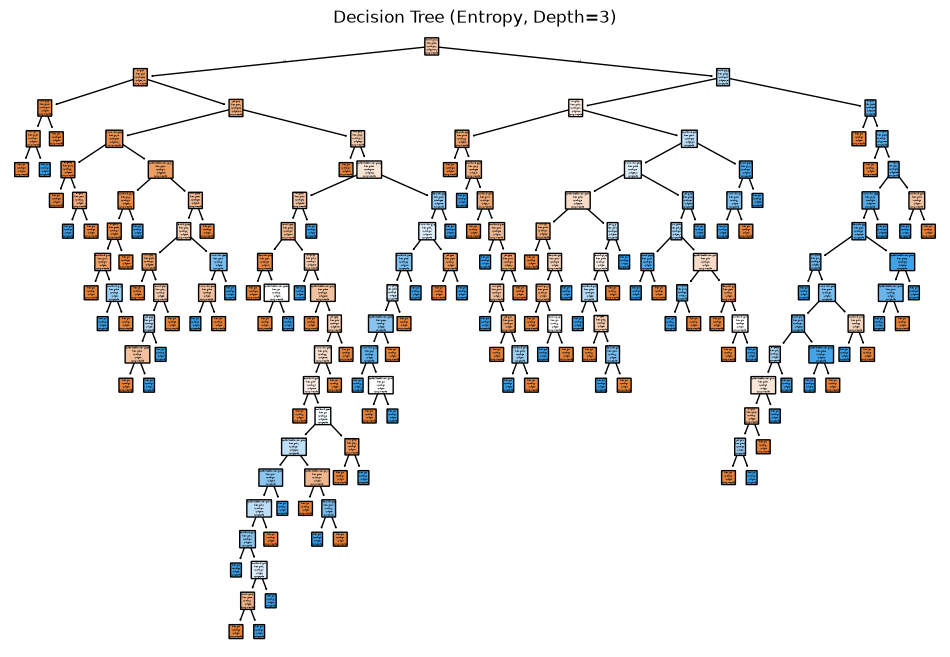

<function matplotlib.pyplot.bar(x: 'float | ArrayLike', height: 'float | ArrayLike', width: 'float | ArrayLike' = 0.8, bottom: 'float | ArrayLike | None' = None, *, align: "Literal['center', 'edge']" = 'center', data: 'DataParamType' = None, **kwargs) -> 'BarContainer'>

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plot_tree(m5['Model Object'], feature_names=X.columns, class_names=['Non-Diabetic', 'Diabetic'], filled=True, rounded=True)
plt.title('Decision Tree (Entropy, Depth=None)')
plt.show()

plt.bar

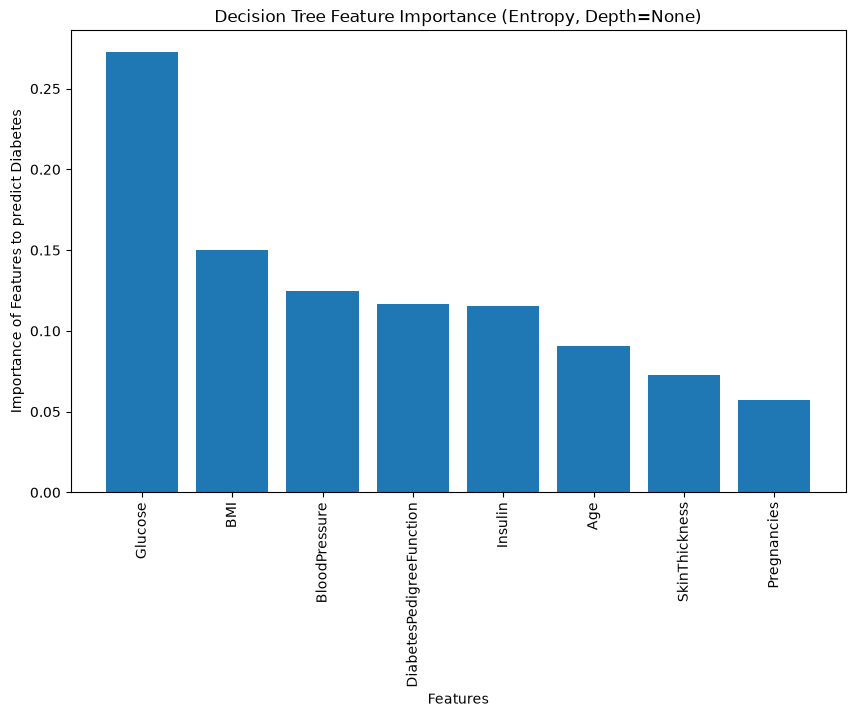

In [11]:
importance = m5['Model Object'].feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)
plt.figure(figsize=(10,6))

plt.bar(
    feature_importance_df['Feature'],
    feature_importance_df['Importance']
)

plt.xticks(rotation=90)
plt.xlabel("Features")
plt.ylabel("Importance of Features to predict Diabetes")
plt.title("Decision Tree Feature Importance (Entropy, Depth=None)")

plt.show()

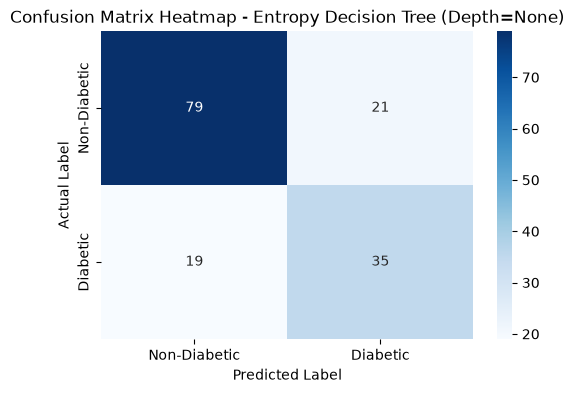

In [12]:
import seaborn as sns
cm = m5['Confusion Matrix']

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix Heatmap - Entropy Decision Tree (Depth=None)")

plt.show()

## 7. Reflection Questions (write short answers, 1–3 sentences each)

1. Which features seemed most important for Decision Trees, and how do you know (from your visualizations or model output)?
2. What was the effect of the hyperparameter(s) you tuned in Section 5? Did performance improve, get worse, or barely change?
3. If you had to explain this model to someone who has never studied ML, what is the one-sentence idea behind it?
4. Compare the unrestricted-depth models (C, D) to the depth-3 models (A, B) -> did letting the tree grow freely improve test accuracy, or is there a sign of overfitting (e.g., very high training accuracy but no test improvement)? Add a quick check: report training accuracy for model C alongside its test accuracy to support your answer.
5. Did Gini and Entropy produce noticeably different trees or similar ones? Which root-node feature did each choose?

1.The most important feature for Decision Tree is glucose as it is the root node of our tree ,we can see it throught the vosulization and also the model outut
2.When the depth were changed from 3 to none the accuracy and f1 score incresed 
3.This model makes decisions by asking a series of simple yes/no questions about the data, splitting it step by step until it can predict the correct category
4               Model  Accuracy  Precision  Recall  F1-score
    0        Gini depth=3     0.688      0.636   0.259     0.368
    1     Entropy depth=3     0.727      0.625   0.556     0.588
    2   Gini depth=NONE     0.656      0.511   0.426     0.465
    3  Entropy depth=None     0.740      0.625   0.648     0.636
5.Gini and Entropy produced similar decision trees, with both choosing Glucose as the root node. They used similar features (Glucose, BMI, Age, and Insulin), but the Entropy model performed better, achieving higher recall and F1-score while maintaining similar precision.

## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ yes] Data loaded and cleaned (Section 2)
- [ yes] Correct train/test split (Section 3)
- [ yes] Model(s) trained with the required libraries (Section 4)
- [ yes] Hyperparameter comparison completed (Section 5)
- [ yes] All 4 required metrics reported (Section 6):
   - Accuracy
   - Precision
   - Recall
   - F1-score
- [ yes] All 3 required visualizations (Section 6):
    - Tree diagram (plot_tree)
    - Feature importance bar chart
    - Confusion matrix heatmap
- [ yes] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Whose model scored highest on Accuracy? On Recall? Are these the same student? (If Applicable)
- If this model were used in a real clinic to screen for diabetes, would you prioritize Precision or Recall? Why? (If Applicable)
- Which visualizations were most convincing for explaining *why* a model performed the way it did?
- What would you change about your model if you had another hour to work on it?
